# Issue #369 — corrected-N7 support-shape contraction x expansion factorial

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/n7_support_shape'

In [2]:
performance=pd.read_csv(OUT/'performance.csv')
contrasts=pd.read_csv(OUT/'contrasts.csv')
import json
dev=json.load(open(OUT/'dev_diagnostic.json'))
print('DEV DIAGNOSTIC PASS:', dev['pass'])
performance.head(8)

DEV DIAGNOSTIC PASS: False


,scope,base,shape,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,hit_rate,payout_cond_hit,pnl_frac_cny
0,2022,R0_CORRECTED,BOTH,51,52224.0,18321.613128,-33902.386872,66097.613128,-0.339024,-0.649173,0.117647,3053.602188,-32680.945996
1,2022,R0_CORRECTED,CONTRACTION_ONLY,51,52224.0,29314.581005,-22909.418995,77090.581005,-0.229094,-0.438676,0.117647,4885.763501,-22909.418995
2,2022,R0_CORRECTED,CONTROL,51,52224.0,47532.938194,-4691.061806,95308.938194,-0.046911,-0.089826,0.215686,4321.176199,-4691.061806
3,2022,R0_CORRECTED,EXPANSION_ONLY,51,52224.0,34099.255123,-18124.744877,81875.255123,-0.181247,-0.347058,0.235294,2841.604594,-17588.389786
4,2022,R3_CORRECTED,BOTH,51,52224.0,40713.304789,-11510.695211,88489.304789,-0.115107,-0.220410,0.098039,8142.660958,-12318.005626
5,2022,R3_CORRECTED,CONTRACTION_ONLY,51,52224.0,30494.702991,-21729.297009,78270.702991,-0.217293,-0.416079,0.058824,10164.900997,-21729.297009
6,2022,R3_CORRECTED,CONTROL,51,52224.0,24417.018861,-27806.981139,72193.018861,-0.278070,-0.532456,0.098039,4883.403772,-27806.981139
7,2022,R3_CORRECTED,EXPANSION_ONLY,51,52224.0,29791.347777,-22432.652223,77567.347777,-0.224327,-0.429547,0.176471,3310.149753,-22026.411859


In [3]:
contrasts

,contrast,issues,lift_cny,ex_largest_lift_cny,bootstrap_p05_cny,bootstrap_median_cny,bootstrap_p95_cny
0,BASE=R0_CORRECTED|EFFECT=contraction,151,32677.270036,45883.010288,-14562.606062,33334.825350,78101.066848
1,BASE=R0_CORRECTED|EFFECT=expansion,151,-11933.292596,-19246.982421,-38334.839685,-11612.404544,14987.425107
2,BASE=R0_CORRECTED|EFFECT=interaction,151,-24233.550833,-16919.861007,-51010.683434,-24583.755652,175.313610
3,BASE=R3_CORRECTED|EFFECT=contraction,151,-16698.487885,44239.894226,-144432.209052,-8736.456909,80396.669199
4,BASE=R3_CORRECTED|EFFECT=expansion,151,-1621.904784,-26761.275204,-52517.343701,-4672.423519,58958.124905
5,BASE=R3_CORRECTED|EFFECT=interaction,151,56516.988313,31377.617893,6290.816377,52719.727616,118395.693532
6,SHAPE=CONTROL|LIFT=R3-R0,151,48683.067460,-12255.314651,-57704.624116,37917.848838,171000.302689
7,SHAPE=CONTRACTION_ONLY|LIFT=R3-R0,151,-692.690461,-37657.324463,-94303.301959,-1734.066306,103202.625136
8,SHAPE=EXPANSION_ONLY|LIFT=R3-R0,151,58994.455272,13290.668689,-26085.659313,53690.584976,167840.501323
9,SHAPE=BOTH|LIFT=R3-R0,151,90369.236496,40090.495657,-13798.074871,86658.190868,212117.098696


In [4]:
dev_check=pd.read_parquet(OUT/'dev_diagnostic.parquet')
dev_check

,base,score,n_observations,n_bins,bin_min_n,spearman_monotonicity,max_bin_calibration_err,global_calibration_err,observed_rate,predicted_mean,monotone_pass,calibration_pass,pass,reason
0,R0_CORRECTED,contraction_score,519,8,64,0.809524,0.073244,0.005602,0.672447,0.666845,True,True,True,
1,R0_CORRECTED,expansion_score,675,8,84,-0.023810,0.195825,0.042109,0.231111,0.189002,False,False,False,
2,R3_CORRECTED,contraction_score,515,8,64,0.880952,0.059272,0.014557,0.675728,0.690285,True,True,True,
3,R3_CORRECTED,expansion_score,675,8,84,0.251502,0.170264,0.018202,0.237037,0.218835,False,False,False,


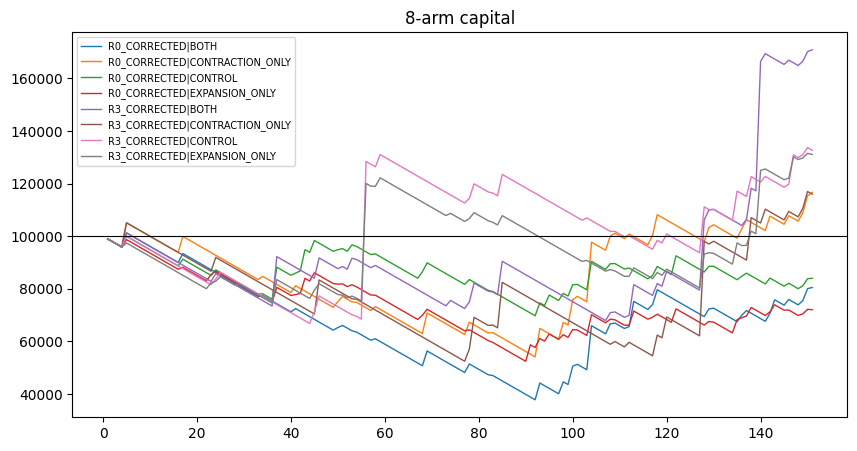

In [5]:
paths=pd.read_csv(OUT/'capital_paths.csv')
fig,ax=plt.subplots(figsize=(10,5))
for (base,shape),g in paths[paths.scope.eq('ALL')].groupby(['base','shape']):
    ax.plot(g.issue_order,g.capital_cny,label=f'{base}|{shape}',lw=1)
ax.axhline(100000,color='black',lw=.8); ax.legend(fontsize=7); ax.set_title('8-arm capital'); plt.show()

In [6]:
b=pd.read_parquet(OUT/'issue_bundles.parquet')
wide=b[b.base.eq('R0_CORRECTED')].pivot(index='issue',columns='shape',values='pnl_cny')
wide[['CONTROL','CONTRACTION_ONLY','EXPANSION_ONLY','BOTH']].describe()

shape,CONTROL,CONTRACTION_ONLY,EXPANSION_ONLY,BOTH
count,151.000000,151.000000,151.000000,151.000000
mean,-105.920141,110.485621,-184.948568,-129.029898
std,2129.604082,3022.554766,1728.687883,2343.083068
min,-1024.000000,-1024.000000,-1024.000000,-1024.000000
25%,-1024.000000,-1024.000000,-1024.000000,-1024.000000
50%,-1024.000000,-1024.000000,-1024.000000,-1024.000000
75%,-528.938986,-1024.000000,-160.717897,-1024.000000
max,12181.740252,22656.401162,7856.150436,16736.300871
